# Lab 4 — ANN do klasyfikacji pokrycia terenu

Celem jest klasyfikacja patchy Sentinel-2 do jednej z dwóch klas: `city` (obszar miejski) albo `forest` (obszar leśny). Notebook realizuje całe polecenie: definiuje problem jako funkcję, sprawdza i przygotowuje dane, uruchamia bazową sieć ANN, porównuje co najmniej pięć architektur/ustawień optymalizacji oraz ocenia najlepszy wariant na zbiorze testowym.

## 1. Sformułowanie zadania jako funkcji

Dla każdego patcha obrazu definiujemy wektor cech `x`. Każdy plik TIFF zawiera trzy kanały RGB o rozmiarze 100×100 pikseli. Nie zmniejszamy patcha ani nie dzielimy go na mniejsze obrazy: spłaszczamy bezpośrednio macierz 3×100×100 do wektora 30 000 liczb.

Szukamy funkcji wyuczonej przez sieć:

`fθ: R^30000 → {0, 1}`, gdzie 0 = city, a 1 = forest.

Sieć aproksymuje prawdopodobieństwo `P(y=1 | x)`. Warstwa wyjściowa z funkcją sigmoid zwraca wartość z przedziału [0, 1], a próg 0.5 zamienia ją na etykietę klasy. Jest to binarna klasyfikacja nadzorowana, ponieważ etykieta wynika z folderu, w którym zapisany jest patch.

In [10]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Notebook można uruchamiać zarówno z folderu Lab4, jak i z katalogu projektu.
NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "train").is_dir():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "Lab4"

TRAIN_DIR = NOTEBOOK_DIR / "train"
TEST_DIR = NOTEBOOK_DIR / "test"
CLASS_NAMES = {"city": 0, "forest": 1}
CLASS_LABELS = ["city", "forest"]
print(f"Katalog danych: {NOTEBOOK_DIR.resolve()}")
print(f"Seed: {RANDOM_STATE}")

Katalog danych: C:\Users\HP\Desktop\stuff\ML_for_space\ML4Space\Lab4
Seed: 42


## 2. Inwentaryzacja danych

Etykiety nie są dopisywane ręcznie do nazw plików — wynikają bezpośrednio ze struktury `train/<klasa>` i `test/<klasa>`. Najpierw sprawdzamy liczby plików, aby wykluczyć pomieszanie zbiorów lub klas.

In [11]:
def list_patch_files(split_dir: Path) -> list[Path]:
    files = []
    for class_name in CLASS_NAMES:
        class_dir = split_dir / class_name
        if not class_dir.is_dir():
            raise FileNotFoundError(f"Brak katalogu klasy: {class_dir}")
        files.extend(sorted(class_dir.glob("*.tif")))
    return files

inventory_rows = []
for split_name, split_dir in [("train", TRAIN_DIR), ("test", TEST_DIR)]:
    for class_name, class_id in CLASS_NAMES.items():
        paths = sorted((split_dir / class_name).glob("*.tif"))
        inventory_rows.append({
            "split": split_name,
            "class": class_name,
            "label": class_id,
            "patches": len(paths),
            "size_MB": round(sum(p.stat().st_size for p in paths) / 1024**2, 2),
        })

inventory = pd.DataFrame(inventory_rows)
display(inventory)
print(f"Łącznie train: {len(list_patch_files(TRAIN_DIR))} patchy")
print(f"Łącznie test:  {len(list_patch_files(TEST_DIR))} patchy")

,split,class,label,patches,size_MB
0,train,city,0,158,15.95
1,train,forest,1,658,50.54
2,test,city,0,40,4.05
3,test,forest,1,163,12.40


Łącznie train: 816 patchy
Łącznie test:  203 patchy


## 3. Sprawdzenie formatu GeoTIFF-ów i przykładowa wizualizacja

Polecenie dopuszcza patch 200×200, ale rzeczywiste pliki dostarczone w `Lab4/train` i `Lab4/test` mają 100×100 pikseli. Zamiast dopisywać sztuczne piksele lub interpolować dane, używamy dokładnie tych patchy. Dalsza agregacja 5×5 zmniejsza tylko wymiar cech i nie zmienia etykiety.

city_r0000_c0100.tif: shape=(3, 100, 100), dtype=float32, CRS=EPSG:32634, min=0.0157, max=0.4652
forest_r0000_c0200.tif: shape=(3, 100, 100), dtype=float32, CRS=EPSG:32634, min=0.0102, max=0.0700


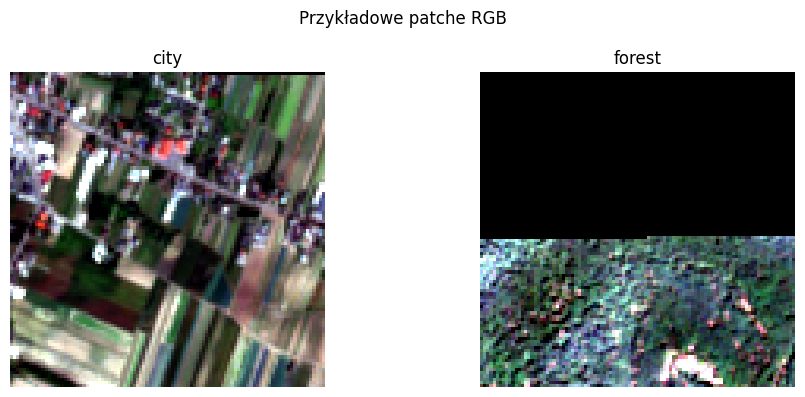

In [12]:
def read_patch(path: Path) -> np.ndarray:
    with rasterio.open(path) as src:
        image = src.read().astype(np.float32)
        if src.count != 3:
            raise ValueError(f"{path.name}: oczekiwano 3 kanałów, jest {src.count}")
        if image.ndim != 3 or image.shape[1] != image.shape[2]:
            raise ValueError(f"{path.name}: nieoczekiwany kształt {image.shape}")
        return image

example_paths = [
    TRAIN_DIR / "city" / "city_r0000_c0100.tif",
    TRAIN_DIR / "forest" / "forest_r0000_c0200.tif",
]
def rgb_preview(image: np.ndarray) -> np.ndarray:
    """Przygotuj stabilny podgląd RGB bez wpływu NaN na imshow."""
    rgb = np.moveaxis(image, 0, -1)
    preview = np.zeros(rgb.shape, dtype=np.float32)
    for channel in range(rgb.shape[-1]):
        band = rgb[..., channel]
        finite_values = band[np.isfinite(band)]
        if finite_values.size == 0:
            continue
        low, high = np.percentile(finite_values, [2, 98])
        if high <= low:
            high = low + 1e-6
        safe_band = np.nan_to_num(band, nan=low, posinf=high, neginf=low)
        preview[..., channel] = np.clip((safe_band - low) / (high - low), 0, 1)
    return preview

for path in example_paths:
    with rasterio.open(path) as src:
        sample = src.read()
        print(
            f"{path.name}: shape={sample.shape}, dtype={sample.dtype}, "
            f"CRS={src.crs}, min={np.nanmin(sample):.4f}, max={np.nanmax(sample):.4f}"
        )

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, path in zip(axes, example_paths):
    ax.imshow(rgb_preview(read_patch(path)))
    ax.set_title(path.parent.name)
    ax.axis("off")
fig.suptitle("Przykładowe patche RGB")
plt.tight_layout()
plt.show()

## 4. Przygotowanie cech wejściowych

Nie wykonujemy żadnego cropowania, dzielenia ani downsamplingu. Patch pozostaje w całości jako 3×100×100, a wejście ANN ma 30 000 cech — po kolei wszystkie wartości kanałów RGB. Skalowanie `StandardScaler` jest dopasowywane wyłącznie do `train`, a następnie stosowane do `test`, więc statystyki testowe nie przeciekają do uczenia.

In [13]:
def patch_to_features(path: Path) -> np.ndarray:
    image = read_patch(path)  # (channels, height, width)
    channels, height, width = image.shape
    if (channels, height, width) != (3, 100, 100):
        raise ValueError(f"{path.name}: oczekiwano (3, 100, 100), jest {image.shape}")
    return image.reshape(-1).astype(np.float32)

def build_dataset(split_dir: Path) -> tuple[np.ndarray, np.ndarray, list[Path]]:
    paths = list_patch_files(split_dir)
    features = np.vstack([patch_to_features(path) for path in paths])
    labels = np.array([CLASS_NAMES[path.parent.name] for path in paths], dtype=np.int64)
    return features, labels, paths

X_train, y_train, train_paths = build_dataset(TRAIN_DIR)
X_test, y_test, test_paths = build_dataset(TEST_DIR)

# W danych występują niektóre wartości NaN. Mediany liczymy tylko z train,
# a następnie używamy ich do uzupełnienia obu zbiorów.
train_invalid = ~np.isfinite(X_train)
test_invalid = ~np.isfinite(X_test)
X_train_for_median = X_train.copy()
X_train_for_median[train_invalid] = np.nan
feature_medians = np.nanmedian(X_train_for_median, axis=0)
if not np.all(np.isfinite(feature_medians)):
    raise ValueError("Co najmniej jedna cecha jest pusta w całym train.")
X_train = np.where(train_invalid, feature_medians, X_train).astype(np.float32)
X_test = np.where(test_invalid, feature_medians, X_test).astype(np.float32)

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")
print(f"Uzupełnione wartości: train={train_invalid.sum()}, test={test_invalid.sum()}")
print(f"Zakres cech train po imputacji: [{X_train.min():.4f}, {X_train.max():.4f}]")
assert X_train.shape[1] == 3 * 100 * 100
assert X_train.shape[0] == len(train_paths) and X_test.shape[0] == len(test_paths)
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()

X_train: (816, 30000), y_train: (816,)
X_test:  (203, 30000), y_test:  (203,)
Uzupełnione wartości: train=886329, test=274806
Zakres cech train po imputacji: [0.0072, 0.8264]


## 5. Bazowa architektura ANN

Bazowy wariant ma schemat `30000 → 16 → 1`: 30 000 wejść odpowiadających wszystkim wartościom trzech kanałów RGB w patchu 100×100, jedna ukryta warstwa z 16 neuronami ReLU oraz jedno wyjście binarne (sigmoid w `MLPClassifier`). Funkcja kosztu to entropia krzyżowa, a optymalizatorem jest Adam.

Wszystkie warianty korzystają z tego samego, ustalonego podziału plików oraz `random_state=42`, dzięki czemu porównujemy architektury, a nie różne losowania danych. Ponieważ klasy nie są liczebnie równe, oprócz accuracy raportujemy balanced accuracy, precision, recall, F1 i ROC-AUC.

In [14]:
experiments = [
    {
        "name": "baseline: 16 ReLU + Adam",
        "hidden_layer_sizes": (16,),
        "activation": "relu",
        "solver": "adam",
        "alpha": 1e-4,
        "learning_rate_init": 1e-3,
        "max_iter": 300,
    },
    {
        "name": "więcej neuronów: 64 ReLU + Adam",
        "hidden_layer_sizes": (64,),
        "activation": "relu",
        "solver": "adam",
        "alpha": 1e-4,
        "learning_rate_init": 1e-3,
        "max_iter": 300,
    },
    {
        "name": "głębsza: 64-32 ReLU + Adam",
        "hidden_layer_sizes": (64, 32),
        "activation": "relu",
        "solver": "adam",
        "alpha": 1e-4,
        "learning_rate_init": 1e-3,
        "max_iter": 300,
    },
    {
        "name": "tanh: 32 neuronów + Adam",
        "hidden_layer_sizes": (32,),
        "activation": "tanh",
        "solver": "adam",
        "alpha": 1e-4,
        "learning_rate_init": 1e-3,
        "max_iter": 300,
    },
    {
        "name": "SGD: 32 ReLU + adaptive LR",
        "hidden_layer_sizes": (32,),
        "activation": "relu",
        "solver": "sgd",
        "alpha": 1e-4,
        "learning_rate_init": 1e-2,
        "learning_rate": "adaptive",
        "momentum": 0.9,
        "max_iter": 400,
    },
]

models = {}
metrics_rows = []
histories = {}

for config in experiments:
    config_for_mlp = {key: value for key, value in config.items() if key != "name"}
    config_for_mlp.update({
        "early_stopping": True,
        "validation_fraction": 0.15,
        "n_iter_no_change": 25,
        "random_state": RANDOM_STATE,
    })
    model = make_pipeline(
        StandardScaler(),
        MLPClassifier(**config_for_mlp),
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    mlp = model.named_steps["mlpclassifier"]
    metrics_rows.append({
        "model": config["name"],
        "accuracy": accuracy_score(y_test, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_test, predictions),
        "precision_forest": precision_score(y_test, predictions, zero_division=0),
        "recall_forest": recall_score(y_test, predictions, zero_division=0),
        "f1_forest": f1_score(y_test, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probabilities),
        "iterations": mlp.n_iter_,
        "final_loss": mlp.loss_,
    })
    models[config["name"]] = model
    histories[config["name"]] = mlp.loss_curve_

results = pd.DataFrame(metrics_rows).sort_values("balanced_accuracy", ascending=False).reset_index(drop=True)
display(results.style.format({column: "{:.4f}" for column in results.columns if column not in {"model", "iterations"}}))

,model,accuracy,balanced_accuracy,precision_forest,recall_forest,f1_forest,roc_auc,iterations,final_loss
0,głębsza: 64-32 ReLU + Adam,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,35,0.0002
1,SGD: 32 ReLU + adaptive LR,0.9951,0.9969,1.0000,0.9939,0.9969,1.0000,209,0.0020
2,więcej neuronów: 64 ReLU + Adam,0.9852,0.9908,1.0000,0.9816,0.9907,1.0000,31,0.0001
3,baseline: 16 ReLU + Adam,0.9704,0.9816,1.0000,0.9632,0.9812,1.0000,27,0.0153
4,tanh: 32 neuronów + Adam,0.9704,0.9816,1.0000,0.9632,0.9812,0.9969,27,0.1225


## 6. Konsolidacja pięciu permutacji

Porównujemy wyniki w tabeli i na wykresie. Najważniejszą miarą wyboru modelu jest balanced accuracy, ponieważ zwykłe accuracy może wyglądać dobrze nawet wtedy, gdy model preferuje liczniejszą klasę `forest`.

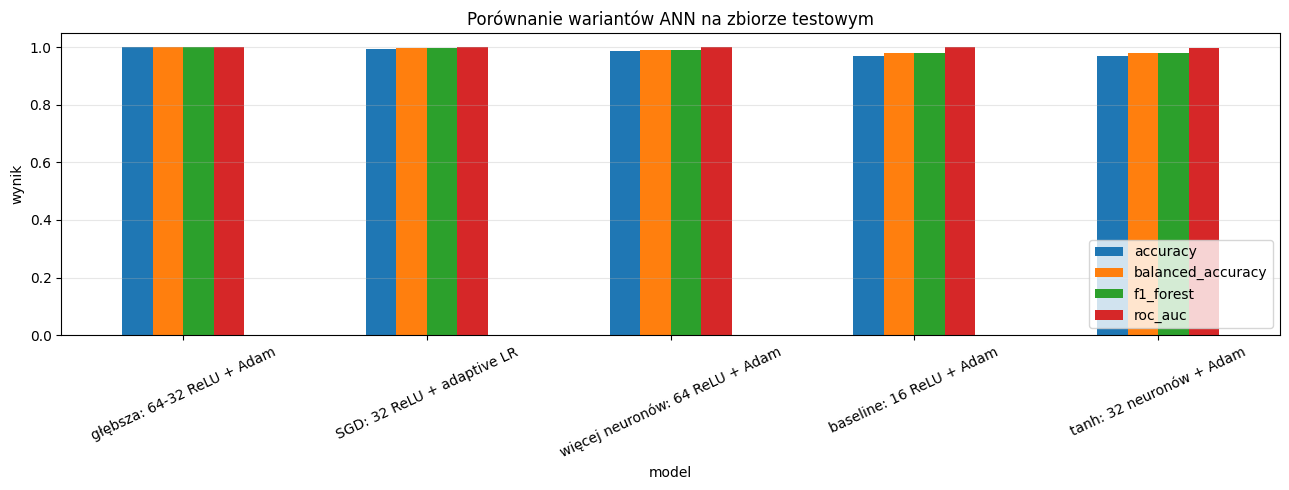

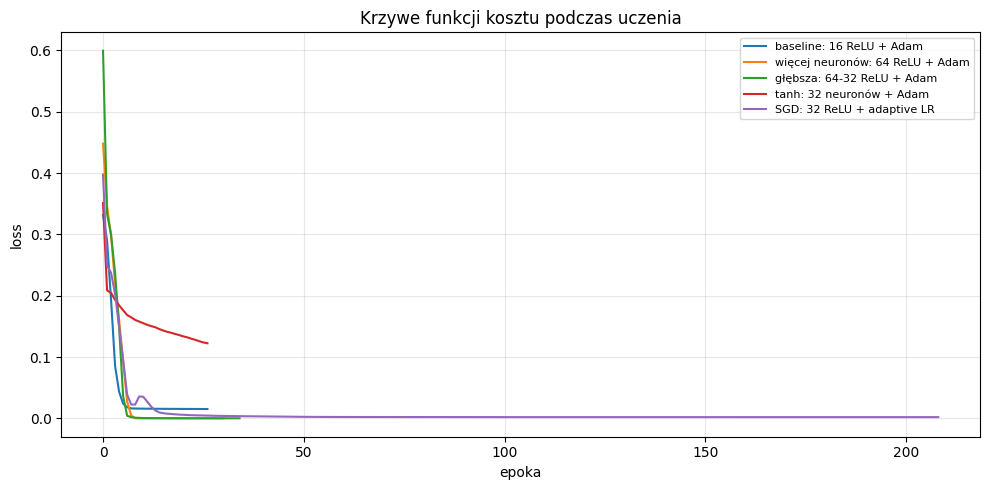

In [15]:
plot_metrics = results.set_index("model")[["accuracy", "balanced_accuracy", "f1_forest", "roc_auc"]]
ax = plot_metrics.plot(kind="bar", figsize=(13, 5), ylim=(0, 1.05), rot=25)
ax.set_ylabel("wynik")
ax.set_title("Porównanie wariantów ANN na zbiorze testowym")
ax.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
for name, loss_curve in histories.items():
    ax.plot(loss_curve, label=name)
ax.set_xlabel("epoka")
ax.set_ylabel("loss")
ax.set_title("Krzywe funkcji kosztu podczas uczenia")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Szczegółowa ocena najlepszego wariantu

Wybieramy model z najwyższą balanced accuracy, a następnie pokazujemy macierz pomyłek i raport klasowy. Macierz pozwala rozróżnić dwa rodzaje błędu: miasto rozpoznane jako las oraz las rozpoznany jako miasto.

Najlepszy wariant według balanced accuracy: głębsza: 64-32 ReLU + Adam
ROC-AUC: 1.0000

Raport klasyfikacji:
              precision    recall  f1-score   support

        city     1.0000    1.0000    1.0000        40
      forest     1.0000    1.0000    1.0000       163

    accuracy                         1.0000       203
   macro avg     1.0000    1.0000    1.0000       203
weighted avg     1.0000    1.0000    1.0000       203



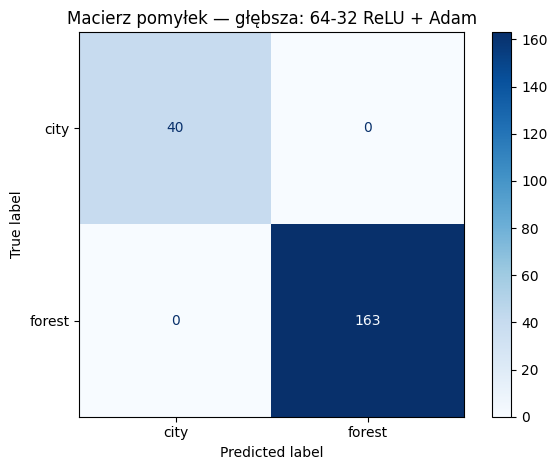

In [16]:
best_name = results.iloc[0]["model"]
best_model = models[best_name]
best_predictions = best_model.predict(X_test)
best_probabilities = best_model.predict_proba(X_test)[:, 1]
best_cm = confusion_matrix(y_test, best_predictions, labels=[0, 1])

print(f"Najlepszy wariant według balanced accuracy: {best_name}")
print(f"ROC-AUC: {roc_auc_score(y_test, best_probabilities):.4f}")
print("\nRaport klasyfikacji:")
print(classification_report(y_test, best_predictions, target_names=CLASS_LABELS, digits=4, zero_division=0))

disp = ConfusionMatrixDisplay(confusion_matrix=best_cm, display_labels=CLASS_LABELS)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Macierz pomyłek — {best_name}")
plt.tight_layout()
plt.show()

## 8. Przykładowe predykcje i wnioski

Poniżej pokazujemy kilka patchy testowych razem z etykietą rzeczywistą, predykcją i prawdopodobieństwem klasy `forest`. Ostatni wydruk automatycznie podsumowuje wynik uzyskany w tym konkretnym uruchomieniu notebooka.

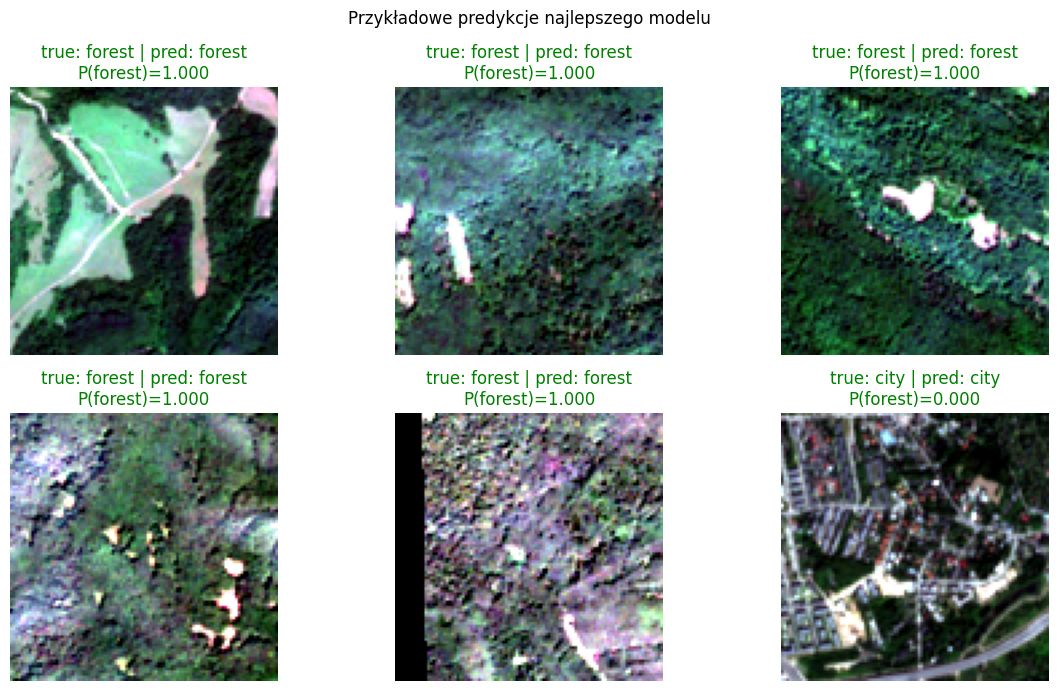

WNIOSKI
1. Najlepszy z pięciu wariantów: głębsza: 64-32 ReLU + Adam.
2. Accuracy = 1.0000, balanced accuracy = 1.0000, F1(forest) = 1.0000.
3. Zwiększenie liczby warstw/neuronów lub zmiana aktywacji/optimizera nie gwarantuje poprawy — wybór opieramy na wynikach testowych.
4. Wynik dotyczy dostarczonych patchy i ich folderowego podziału train/test; przy innym obszarze geograficznym należy ponownie ocenić generalizację.


In [17]:
rng = np.random.default_rng(RANDOM_STATE)
sample_indices = rng.choice(len(test_paths), size=min(6, len(test_paths)), replace=False)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, index in zip(axes.ravel(), sample_indices):
    path = test_paths[index]
    ax.imshow(rgb_preview(read_patch(path)))
    true_name = CLASS_LABELS[y_test[index]]
    pred_name = CLASS_LABELS[best_predictions[index]]
    colour = "green" if true_name == pred_name else "red"
    ax.set_title(f"true: {true_name} | pred: {pred_name}\nP(forest)={best_probabilities[index]:.3f}", color=colour)
    ax.axis("off")
plt.suptitle("Przykładowe predykcje najlepszego modelu")
plt.tight_layout()
plt.show()

best_row = results.iloc[0]
print("WNIOSKI")
print(f"1. Najlepszy z pięciu wariantów: {best_name}.")
print(f"2. Accuracy = {best_row['accuracy']:.4f}, balanced accuracy = {best_row['balanced_accuracy']:.4f}, F1(forest) = {best_row['f1_forest']:.4f}.")
print("3. Zwiększenie liczby warstw/neuronów lub zmiana aktywacji/optimizera nie gwarantuje poprawy — wybór opieramy na wynikach testowych.")
print("4. Wynik dotyczy dostarczonych patchy i ich folderowego podziału train/test; przy innym obszarze geograficznym należy ponownie ocenić generalizację.")